# Data science lifecycle: assignment 1
## Which variables drive car price? Exploratory analysis of `automobileEDA.csv`
Repo: [Github](https://github.com/macmukasa/Data-Lifecycle-Assignment-1)



In [1]:
#Importing libraries and setting up the environment

import warnings
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from sklearn.feature_selection import f_regression
import statsmodels.api as sm
from statsmodels.formula.api import ols

sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.width", 160, "display.max_columns", 40)

# Reading the dataset
raw = pd.read_csv("automobileEDA.csv")
df = raw.copy()
print("Raw data shape:", raw.shape)
raw.head()

Raw data shape: (201, 29)


,symboling,normalized-losses,make,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,width,height,curb-weight,engine-type,num-of-cylinders,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price,city-L/100km,horsepower-binned,diesel,gas
0,3,122,alfa-romero,std,two,convertible,rwd,front,88.6,0.811148,0.890278,48.8,2548,dohc,four,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,13495.0,11.190476,Medium,0,1
1,3,122,alfa-romero,std,two,convertible,rwd,front,88.6,0.811148,0.890278,48.8,2548,dohc,four,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,16500.0,11.190476,Medium,0,1
2,1,122,alfa-romero,std,two,hatchback,rwd,front,94.5,0.822681,0.909722,52.4,2823,ohcv,six,152,mpfi,2.68,3.47,9.0,154.0,5000.0,19,26,16500.0,12.368421,Medium,0,1
3,2,164,audi,std,four,sedan,fwd,front,99.8,0.848630,0.919444,54.3,2337,ohc,four,109,mpfi,3.19,3.40,10.0,102.0,5500.0,24,30,13950.0,9.791667,Medium,0,1
4,2,164,audi,std,four,sedan,4wd,front,99.4,0.848630,0.922222,54.3,2824,ohc,five,136,mpfi,3.19,3.40,8.0,115.0,5500.0,18,22,17450.0,13.055556,Medium,0,1


The raw dataset has 201 rows and 29 columns. 
Each record represents a car model described by dimensions, engine specifications, fuel economy ratings, body types, and a final price.

## Q1. Feature exploration and data cleaning
### Structure and data types

In [2]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 201 entries, 0 to 200
Data columns (total 29 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   symboling          201 non-null    int64  
 1   normalized-losses  201 non-null    int64  
 2   make               201 non-null    str    
 3   aspiration         201 non-null    str    
 4   num-of-doors       201 non-null    str    
 5   body-style         201 non-null    str    
 6   drive-wheels       201 non-null    str    
 7   engine-location    201 non-null    str    
 8   wheel-base         201 non-null    float64
 9   length             201 non-null    float64
 10  width              201 non-null    float64
 11  height             201 non-null    float64
 12  curb-weight        201 non-null    int64  
 13  engine-type        201 non-null    str    
 14  num-of-cylinders   201 non-null    str    
 15  engine-size        201 non-null    int64  
 16  fuel-system        201 non-null    st

In [3]:
# Determine the summary stats for the dataset.

df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
symboling,201.0,NaN,NaN,NaN,0.840796,1.254802,-2.0,0.0,1.0,2.0,3.0
normalized-losses,201.0,NaN,NaN,NaN,122.0,31.99625,65.0,101.0,122.0,137.0,256.0
make,201,22,toyota,32,NaN,NaN,NaN,NaN,NaN,NaN,NaN
aspiration,201,2,std,165,NaN,NaN,NaN,NaN,NaN,NaN,NaN
num-of-doors,201,2,four,115,NaN,NaN,NaN,NaN,NaN,NaN,NaN
body-style,201,5,sedan,94,NaN,NaN,NaN,NaN,NaN,NaN,NaN
drive-wheels,201,3,fwd,118,NaN,NaN,NaN,NaN,NaN,NaN,NaN
engine-location,201,2,front,198,NaN,NaN,NaN,NaN,NaN,NaN,NaN
wheel-base,201.0,NaN,NaN,NaN,98.797015,6.066366,86.6,94.5,97.0,102.4,120.9
length,201.0,NaN,NaN,NaN,0.837102,0.059213,0.678039,0.801538,0.832292,0.881788,1.0


In [4]:
# Specifying the continuous and categorical predictors, and the target variable.

CONT = ["wheel-base","height","curb-weight","engine-size","bore","stroke","compression-ratio",
        "horsepower","peak-rpm","city-mpg","highway-mpg"]
CAT  = ["symboling","make","aspiration","num-of-doors","body-style","drive-wheels","engine-location",
        "engine-type","num-of-cylinders","fuel-system"]
TARGET = "price"
print("Predictor candidates:", len(CONT), "continuous,", len(CAT), "categorical")
print("Target variable:", TARGET)

Predictor candidates: 11 continuous, 10 categorical
Target variable: price


I split the predictor candidates into 11 continuous features and 10 categorical attributes, with price as the target. The raw file contains several columns like normalized length, normalized width, and city-L/100km that duplicate original measurements. Normalized-losses is excluded as it doesn't speak to price of the cars directly.

### Missing values

Checking for NaN values in the dataset.

In [5]:
missing = pd.DataFrame({"NaN": raw.isna().sum()})
print(missing[missing.sum(axis=1) > 0] if missing.sum().sum() else "No missing values or '?' placeholders found.")

                   NaN
stroke               4
horsepower-binned    1


Missing values exist in two columns: stroke has 4 missing entries and horsepower-binned has 1 missing entry. The other 27 columns are complete.

### Duplicates

In [6]:
print("Fully identical rows:", raw.duplicated().sum())
feat_cols = [c for c in raw.columns if c != TARGET]
print("Rows identical on every predictor (price may differ):", raw.duplicated(subset=feat_cols).sum())
raw[raw.duplicated(subset=feat_cols, keep=False)].sort_values(feat_cols)[["make", "body-style", "curb-weight", "engine-size", "price"]].head(10)

Fully identical rows: 0
Rows identical on every predictor (price may differ): 7


,make,body-style,curb-weight,engine-size,price
57,mazda,sedan,2410,122,8495.0
59,mazda,sedan,2410,122,10245.0
109,peugot,sedan,3252,152,16900.0
113,peugot,sedan,3252,152,17950.0
56,mazda,hatchback,2385,122,8845.0
58,mazda,hatchback,2385,122,10595.0
24,dodge,sedan,1989,90,6692.0
25,dodge,sedan,1989,90,7609.0
0,alfa-romero,convertible,2548,130,13495.0
1,alfa-romero,convertible,2548,130,16500.0


The raw dataset has zero fully identical rows. However, 7 rows share identical values across all predictor attributes while having different prices. For instance, two Alfa Romeo convertibles have the same curb weight of 2,548 and engine size of 130, but one is priced at 13,495 and the other at 16,500. This indicates differences in trim level or options that are not recorded in the feature set.

### Outliers (IQR rule)
A value is flagged when it lies more than 1.5 × IQR outside the quartiles.

In [7]:
# Creating the function to calculate the IQR bounds for outlier detection.

def iqr_bounds(s):
    q1, q3 = s.quantile([.25, .75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

rows = []
for c in CONT + [TARGET]:
    lo, hi = iqr_bounds(df[c])
    rows.append([c, lo, hi, (df[c] < lo).sum(), (df[c] > hi).sum()])
outl = pd.DataFrame(rows, columns=["variable","lower fence","upper fence","n below","n above"]).set_index("variable")
outl.round(2)

,lower fence,upper fence,n below,n above
variable,,,,
wheel-base,82.65,114.25,0,3
height,46.75,60.75,0,0
curb-weight,1033.50,4061.50,0,2
engine-size,33.50,205.50,0,10
bore,2.50,4.23,0,0
stroke,2.66,3.86,15,5
compression-ratio,7.40,10.60,6,21
horsepower,1.00,185.00,0,5
peak-rpm,3750.00,6550.00,0,2


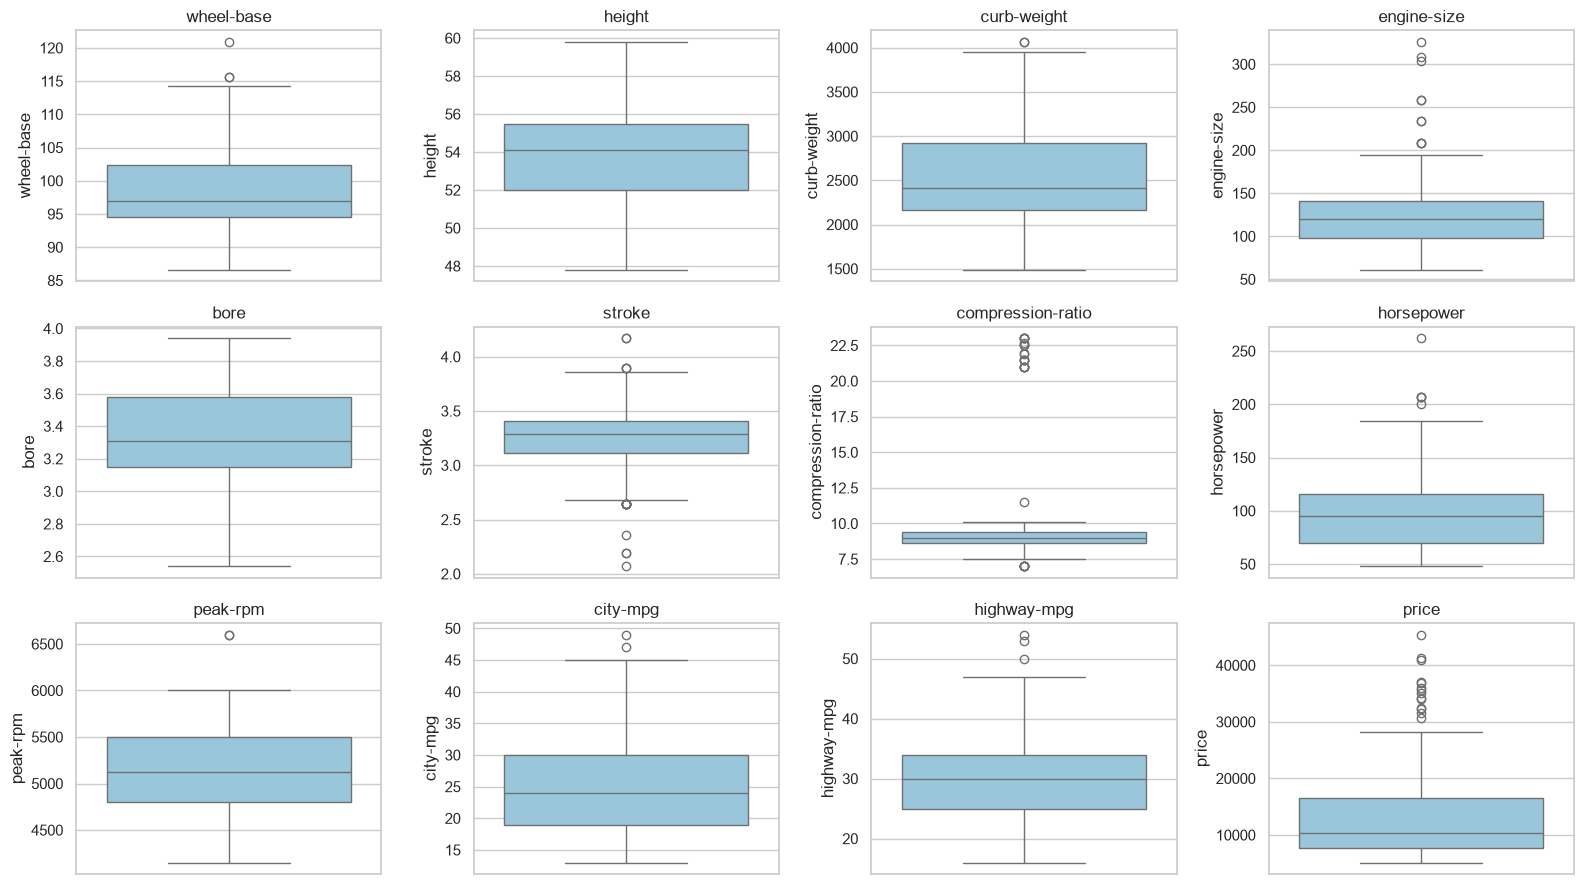

In [8]:
#Plotting boxplots for the continuous predictors and the target variable.

fig, axes = plt.subplots(3, 4, figsize=(16, 9))
for ax, c in zip(axes.ravel(), CONT + [TARGET]):
    sns.boxplot(y=df[c], ax=ax, color="#8ecae6")
    ax.set_title(c)
plt.tight_layout()
plt.show()

The 1.5 IQR rule flags outliers across 9 of the 11 continuous variables as well as the target variable price. Price has 14 cars above its upper fence of 29,587.50. Compression ratio has 21 values above 10.60 and 6 below 7.40. Engine size has 10 values above 205.50. Stroke has 15 values below 2.66 and 5 above 3.86. Height and bore have zero values outside their fences. The high compression ratio values correspond to diesel engines, which require elevated compression to ignite fuel. Capping these points brings diesel compression ratios down to 10.60, reducing the gap between diesel and gas engines in this feature.

### Treatment of Missing Values, Derived Columns & Outliers
Missing continuous values are filled with the column median, which is robust to outliers. Outliers are capped at the IQR fences so all rows are kept. Derived columns are dropped because they repeat information: normalized length and width, city-L/100km, horsepower-binned, and the diesel and gas indicator columns.

In [9]:
for c in CONT + [TARGET]:
    df[c] = df[c].fillna(df[c].median())
    lo, hi = iqr_bounds(df[c])
    df[c] = df[c].clip(lo, hi)

DERIVED = ["length","width","city-L/100km","horsepower-binned","diesel","gas"]
df = df.drop(columns=DERIVED).drop_duplicates().reset_index(drop=True)
df[CAT] = df[CAT].astype(str)

# Saving the cleaned dataset to a CSV file.
df.to_csv(f"Mukasa_Data.csv", index=False)
print("Cleaned shape:", df.shape, "| missing:", int(df.isna().sum().sum()))
print("Saved cleaned dataset to", f"Mukasa_Data.csv")

Cleaned shape: (200, 23) | missing: 0
Saved cleaned dataset to Mukasa_Data.csv


I filled the 4 missing stroke values with the column median of 3.29. Capping price at 29,587.50 caused two Porsche hardtops with previously distinct prices (32,528 and 34,028) to become identical across all remaining columns, so removing identical rows reduced the dataset from 201 to 200 rows. Dropping diesel and gas removes fuel type as an explicit column, so fuel type is now represented only through fuel-system, where idi denotes diesel vehicles. The cleaned dataset has 200 rows and 23 columns with zero missing values.

## Q2. Patterns and descriptive statistics
### Continuous variables

In [10]:
# Calculating summary statistics for the continuous predictors and the target variable.

summary = df[CONT + [TARGET]].describe().T
summary["skew"] = df[CONT + [TARGET]].skew()
summary.round(2)

,count,mean,std,min,25%,50%,75%,max,skew
wheel-base,200.0,98.80,5.90,86.60,94.50,97.00,102.40,114.25,0.92
height,200.0,53.78,2.45,47.80,52.00,54.10,55.52,59.80,0.02
curb-weight,200.0,2554.62,518.27,1488.00,2163.00,2414.00,2928.25,4061.50,0.71
engine-size,200.0,124.07,33.22,61.00,97.75,119.50,141.00,205.50,0.90
bore,200.0,3.33,0.27,2.54,3.15,3.31,3.58,3.94,-0.03
stroke,200.0,3.27,0.28,2.66,3.12,3.29,3.41,3.86,-0.41
compression-ratio,200.0,9.03,0.79,7.40,8.57,9.00,9.40,10.60,0.09
horsepower,200.0,102.21,34.65,48.00,70.00,95.00,116.00,185.00,0.81
peak-rpm,200.0,5113.25,474.53,4150.00,4800.00,5125.37,5500.00,6550.00,0.09
city-mpg,200.0,25.20,6.36,13.00,19.00,24.00,30.00,46.50,0.61


The summary table shows that price has a mean of 12,678.66 and a median of 10,270.00, spanning from 5,118.00 to the capped ceiling of 29,587.50. The positive skewness of 1.24 indicates that price retains a right tail even after capping. Curb weight averages 2,554.62 pounds with a standard deviation of 518.27 pounds, while engine size averages 124.07. Skewness is positive for wheel-base (0.92), engine-size (0.90), and horsepower (0.81). Bore (-0.03) and height (0.02) have distributions close to symmetric.

### Categorical variables

In [11]:
for c in CAT:
    vc = df[c].value_counts()
    print(f"\n{c}")
    print(pd.DataFrame({"count": vc, "percent": (vc/len(df)*100).round(1)}).to_string())


symboling
           count  percent
symboling                
0             65     32.5
1             52     26.0
2             32     16.0
3             26     13.0
-1            22     11.0
-2             3      1.5

make
               count  percent
make                         
toyota            32     16.0
nissan            18      9.0
mazda             17      8.5
honda             13      6.5
mitsubishi        13      6.5
subaru            12      6.0
volkswagen        12      6.0
peugot            11      5.5
volvo             11      5.5
dodge              9      4.5
bmw                8      4.0
mercedes-benz      8      4.0
plymouth           7      3.5
audi               6      3.0
saab               6      3.0
alfa-romero        3      1.5
chevrolet          3      1.5
jaguar             3      1.5
porsche            3      1.5
isuzu              2      1.0
renault            2      1.0
mercury            1      0.5

aspiration
            count  percent
aspiration      

Several categorical attributes have heavily unbalanced distributions. Engine location is front for 198 cars (99.0%) and rear for only 2 cars (1.0%). Front wheel drive makes up 118 cars (59.0%), rear wheel drive has 74 cars (37.0%), and four wheel drive has 8 cars (4.0%). In body style, sedans and hatchbacks account for 94 cars (47.0%) and 68 cars (34.0%), while convertibles and hardtops have only 6 cars (3.0%) and 7 cars (3.5%). Four-cylinder engines dominate cylinder count with 157 cars (78.5%), while three-cylinder and twelve-cylinder configurations have only 1 car each. These small group sizes mean statistical conclusions for rare classes carry high uncertainty.

### Distribution of price

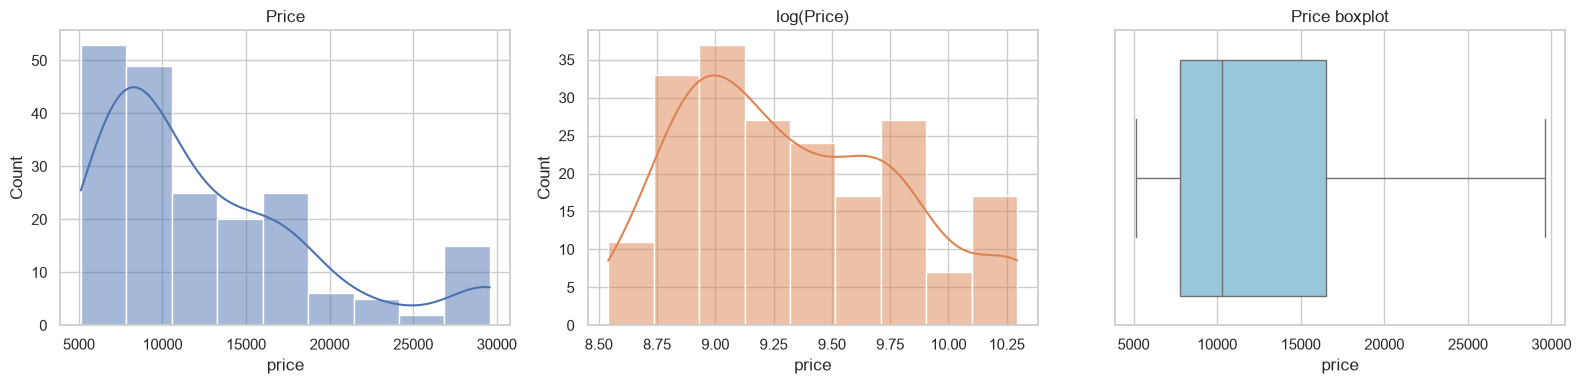

Skewness raw: 1.24 | log: 0.46


In [12]:
# Plotting the distribution of the target variable and its log transformation.

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(df[TARGET], kde=True, ax=ax[0])
ax[0].set_title("Price")
sns.histplot(np.log(df[TARGET]), kde=True, ax=ax[1], color="C1")
ax[1].set_title("log(Price)")
sns.boxplot(x=df[TARGET], ax=ax[2], color="#8ecae6")
ax[2].set_title("Price boxplot")
plt.tight_layout()
plt.show()
print("Skewness raw:", round(df[TARGET].skew(), 2), "| log:", round(np.log(df[TARGET]).skew(), 2))

The raw price distribution concentrates between 6,000 and 12,000 with a long right tail. Taking the logarithm reduces skewness from 1.24 to 0.46, bringing the shape closer to a bell curve. The boxplot shows the concentration of capped cars at the upper fence of 29,587.50.

### Distribution of the other variables

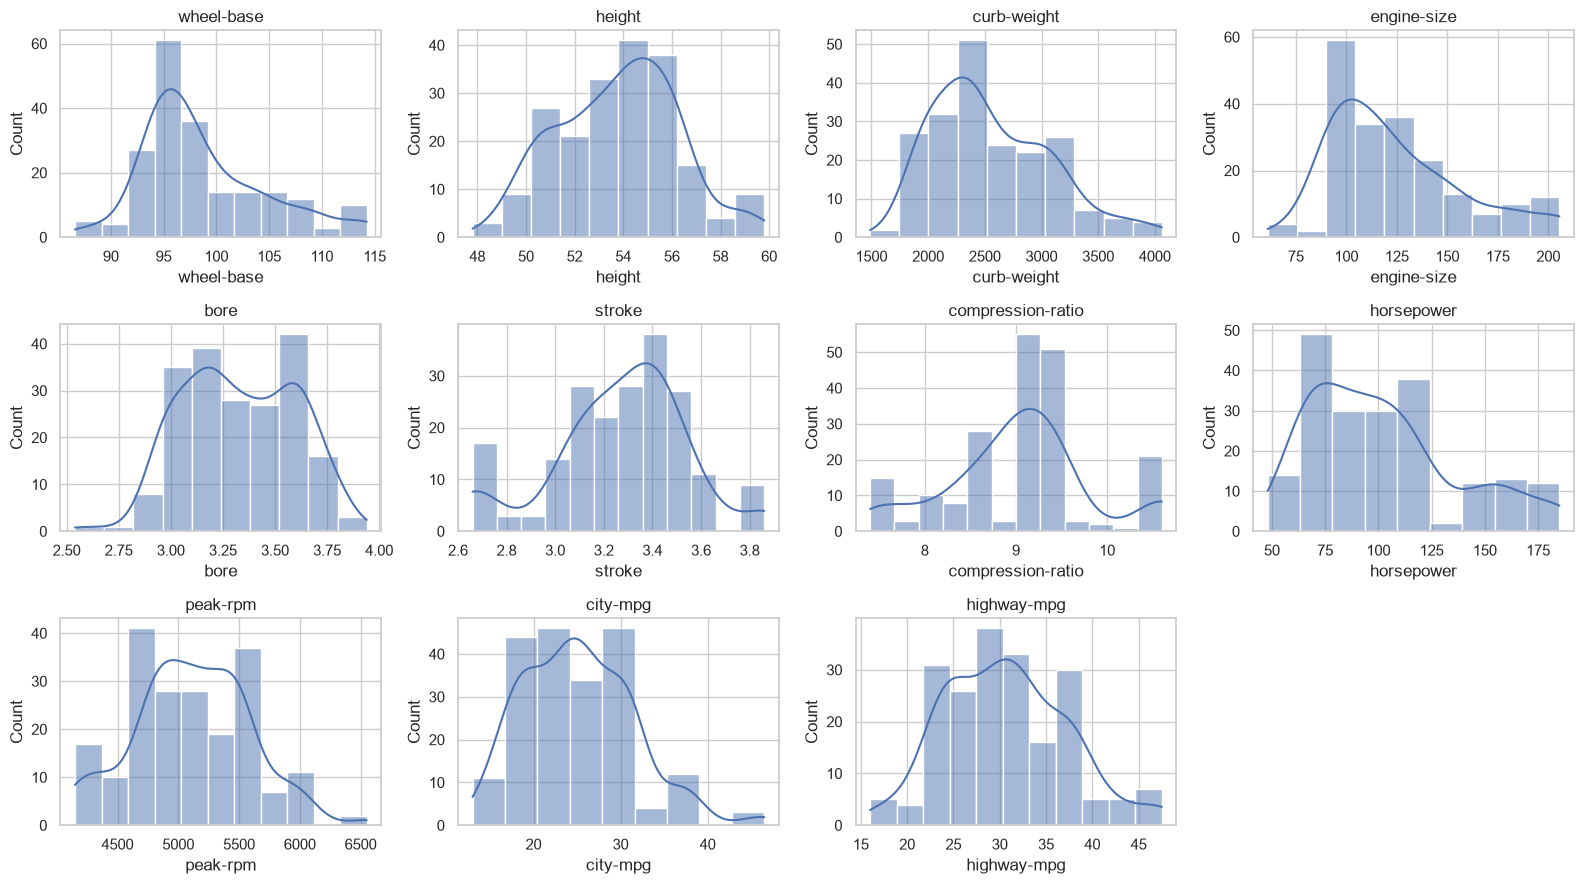

In [13]:
# Plotting the distribution of the continuous predictors.

fig, axes = plt.subplots(3, 4, figsize=(16, 9))
for ax, c in zip(axes.ravel(), CONT):
    sns.histplot(df[c], kde=True, ax=ax)
    ax.set_title(c)
axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.show()

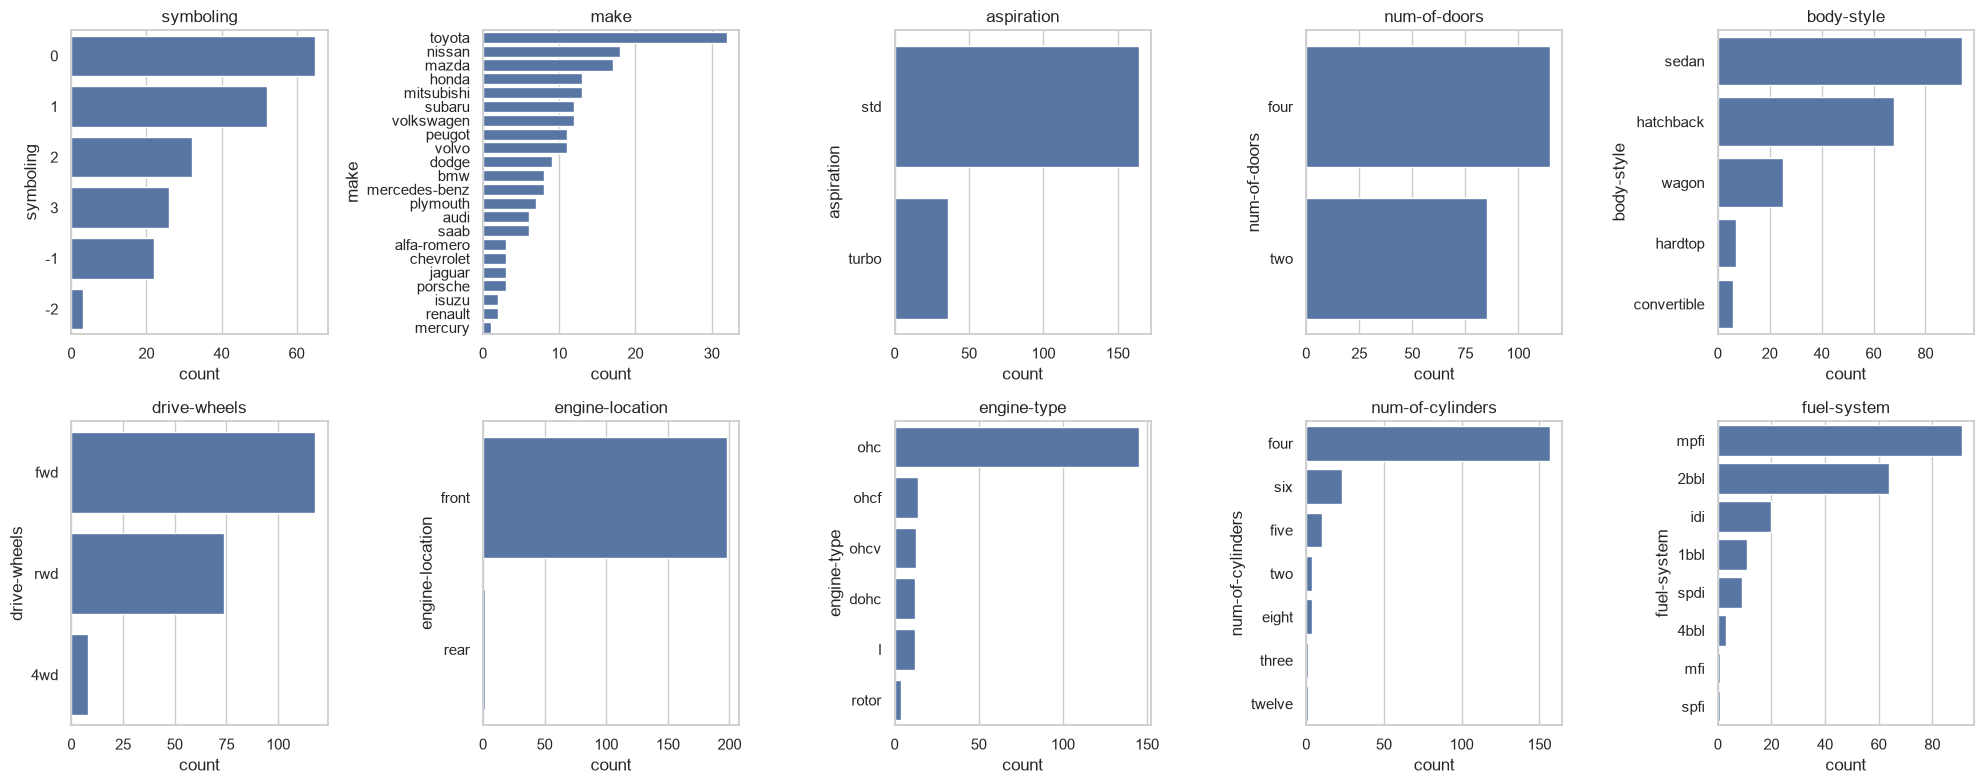

In [14]:
# Plotting the distribution of the categorical predictors.

fig, axes = plt.subplots(2, 5, figsize=(20, 8))
for ax, c in zip(axes.ravel(), CAT):
    order = df[c].value_counts().index
    sns.countplot(y=df[c], order=order, ax=ax)
    ax.set_title(c)
plt.tight_layout()
plt.show()

Continuous variables such as curb weight, engine size, and horsepower are right skewed, mirroring the shape of car price. City mpg and highway mpg display two distinct peaks, separating smaller commuter cars from larger vehicles. In the categorical plots, Toyota is the largest manufacturer with 32 vehicles, followed by Nissan with 18 vehicles and Mazda with 17 vehicles. Standard aspiration accounts for 164 cars (82.0%), and overhead camshaft engines account for 145 cars (72.5%).

## Q3. Average price by group
### Drive wheels and body style

In [15]:
# Calculating the average price by categorical predictors.

def group_stats(col):
    g = df.groupby(col)[TARGET].agg(["count","mean","median","std","min","max"]).sort_values("mean", ascending=False)
    return g.round(0)

for col in ["drive-wheels", "body-style"]:
    g = group_stats(col)
    print(f"\nAverage price by {col}")
    print(g.to_string())
    print(f"Highest: {g['mean'].idxmax()} ({g['mean'].max():,.0f}) | Lowest: {g['mean'].idxmin()} ({g['mean'].min():,.0f})")


Average price by drive-wheels
              count     mean   median     std     min      max
drive-wheels                                                  
rwd              74  18418.0  16872.0  6749.0  6785.0  29588.0
4wd               8  10241.0   9006.0  3288.0  7603.0  17450.0
fwd             118   9245.0   8192.0  3346.0  5118.0  23875.0
Highest: rwd (18,418) | Lowest: fwd (9,245)

Average price by body-style
             count     mean   median      std      min      max
body-style                                                     
convertible      6  19739.0  17084.0   7926.0  11595.0  29588.0
hardtop          7  17841.0  11199.0  10602.0   8249.0  29588.0
sedan           94  13894.0  11078.0   7098.0   5499.0  29588.0
wagon           25  12372.0  11694.0   5121.0   6918.0  28248.0
hatchback       68   9957.0   8672.0   4149.0   5118.0  22018.0
Highest: convertible (19,739) | Lowest: hatchback (9,957)


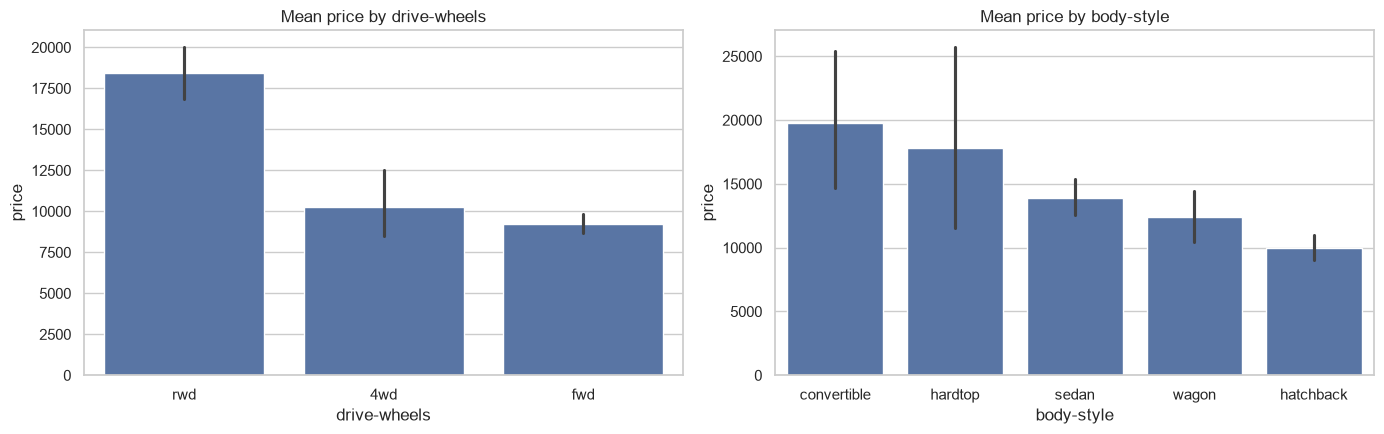

In [16]:
# Visualizing the average price by categorical predictors.

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, col in zip(axes, ["drive-wheels", "body-style"]):
    order = df.groupby(col)[TARGET].mean().sort_values(ascending=False).index
    sns.barplot(data=df, x=col, y=TARGET, order=order, ax=ax, errorbar="ci")
    ax.set_title(f"Mean price by {col}")
plt.tight_layout()
plt.show()

Rear wheel drive has the highest average price among drive wheels at 18,418, while front wheel drive has the lowest average price at 9,245. Four wheel drive cars average 10,241 across 8 vehicles. Among body styles, convertibles have the highest average price at 19,739, followed by hardtops at 17,841 and sedans at 13,894. Hatchbacks have the lowest average price at 9,957. The bar charts show wide confidence intervals for convertibles and hardtops because these two groups contain only 6 and 7 cars.

### Drive wheels × body style

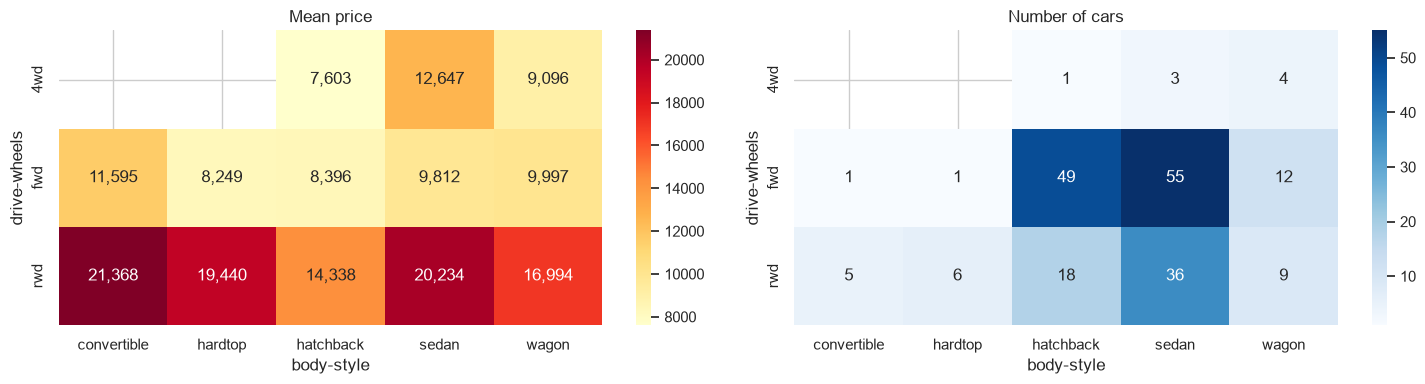

Highest cell: ('rwd', 'convertible') 21368 | Lowest cell: ('4wd', 'hatchback') 7603


In [17]:
# Creating pivot tables for the average price and counts by drive-wheels and body-style.

pivot = df.pivot_table(index="drive-wheels", columns="body-style", values=TARGET, aggfunc="mean")
counts = df.pivot_table(index="drive-wheels", columns="body-style", values=TARGET, aggfunc="count")

# Visualizing the pivot tables as heatmaps.

fig, ax = plt.subplots(1, 2, figsize=(15, 4))
sns.heatmap(pivot, annot=True, fmt=",.0f", cmap="YlOrRd", ax=ax[0])
ax[0].set_title("Mean price")
sns.heatmap(counts, annot=True, fmt=".0f", cmap="Blues", ax=ax[1])
ax[1].set_title("Number of cars")
plt.tight_layout()
plt.show()
stack = pivot.stack()
print("Highest cell:", stack.idxmax(), round(stack.max()), "| Lowest cell:", stack.idxmin(), round(stack.min()))

Rear wheel drive convertibles have the highest average price at 21,368 across 5 vehicles. Four wheel drive hatchbacks have the lowest cell price at 7,603, but this represents a single car. Front wheel drive hardtops and convertibles also contain only 1 vehicle each, with averages of 8,249 and 11,595. These single-car cells cannot support firm pricing comparisons. Rear wheel drive sedans provide a more stable comparison, with 36 cars averaging 20,234.

### Other groupings: make, engine type, cylinders

In [18]:
# Calculating the average price by categorical predictors.

for col in ["make", "engine-type", "num-of-cylinders"]:
    g = group_stats(col)
    print(f"\nAverage price by {col}")
    print(g.to_string())
    print(f"Highest: {g['mean'].idxmax()} ({g['mean'].max():,.0f}) | Lowest: {g['mean'].idxmin()} ({g['mean'].min():,.0f})")


Average price by make
               count     mean   median     std      min      max
make                                                            
jaguar             3  29588.0  29588.0     0.0  29588.0  29588.0
mercedes-benz      8  28739.0  29588.0  1430.0  25552.0  29588.0
porsche            3  27064.0  29588.0  4370.0  22018.0  29588.0
bmw                8  23595.0  22835.0  5575.0  16430.0  29588.0
volvo             11  18063.0  18420.0  3315.0  12940.0  22625.0
audi               6  17859.0  17580.0  3452.0  13950.0  23875.0
mercury            1  16503.0  16503.0     NaN  16503.0  16503.0
alfa-romero        3  15498.0  16500.0  1735.0  13495.0  16500.0
peugot            11  15489.0  16630.0  2247.0  11900.0  18150.0
saab               6  15223.0  15275.0  2861.0  11850.0  18620.0
mazda             17  10653.0  10595.0  3976.0   5195.0  18344.0
nissan            18  10416.0   8124.0  4477.0   5499.0  19699.0
volkswagen        12  10078.0   9738.0  2179.0   7775.0  13845.0
to

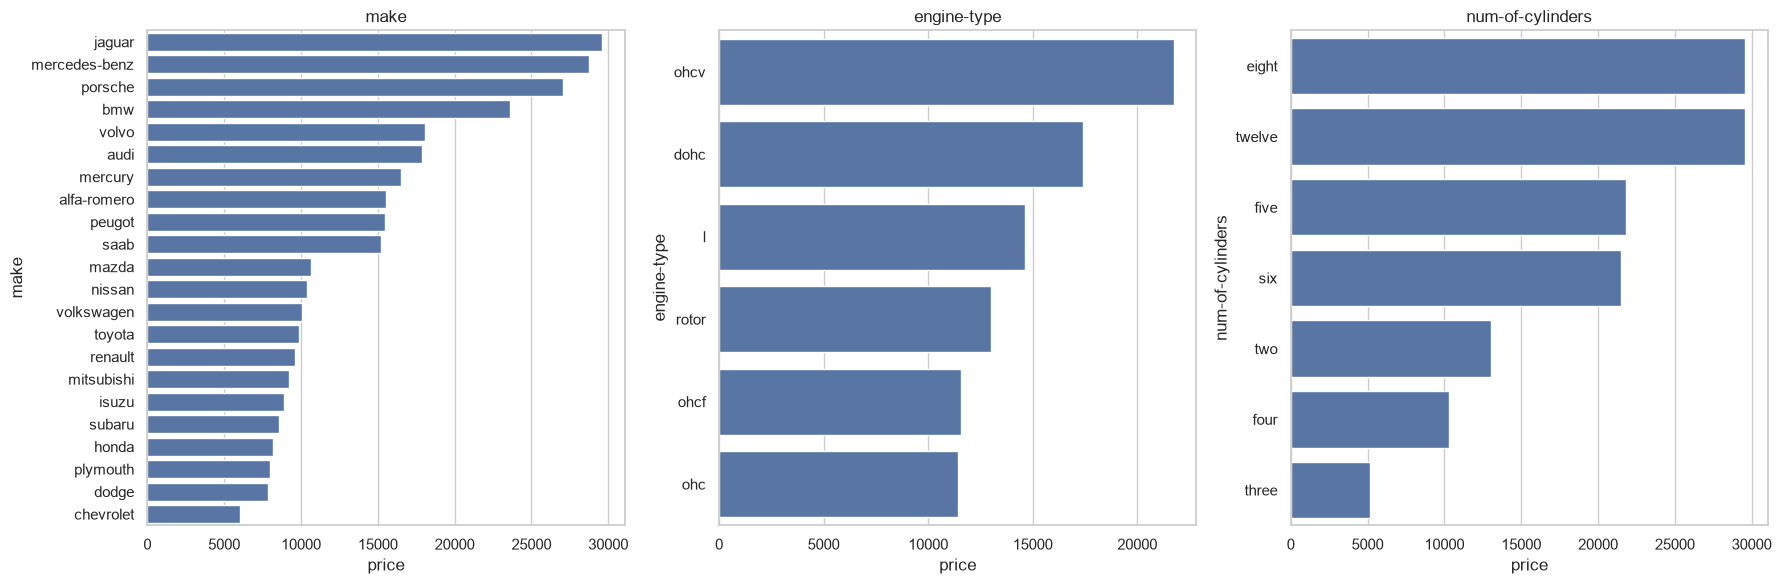

In [19]:
# Visualizing the average price by categorical predictors.

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, col in zip(axes, ["make", "engine-type", "num-of-cylinders"]):
    order = df.groupby(col)[TARGET].mean().sort_values(ascending=False).index
    sns.barplot(data=df, y=col, x=TARGET, order=order, ax=ax, errorbar=None)
    ax.set_title(col)
plt.tight_layout()
plt.show()

Jaguar has the highest average price by make at 29,588 across 3 cars, with Mercedes-Benz second at 28,739 across 8 cars. Chevrolet has the lowest average price at 6,007 across 3 cars, followed by Dodge at 7,875 across 9 cars. For engine type, overhead camshaft V-engines (ohcv) have the highest average price at 21,740 across 13 cars, while standard ohc engines have the lowest average at 11,414 across 145 cars. For cylinder count, eight-cylinder cars and the single twelve-cylinder car average 29,588, while the single three-cylinder car has the lowest price at 5,151. Small counts for Mercury (1 car), twelve-cylinder (1 car), and three-cylinder (1 car) limit the reliability of their group averages.

## Q4. Effect of each attribute on price
### Continuous variables vs price

In [20]:
# Calculating the correlation coefficients and p-values for the continuous predictors and the target variable.

rows = []
for c in CONT:
    r, p = stats.pearsonr(df[c], df[TARGET])
    rs, ps = stats.spearmanr(df[c], df[TARGET])
    rows.append([c, r, p, rs, ps])
corr = pd.DataFrame(rows, columns=["variable","pearson r","p (pearson)","spearman rho","p (spearman)"]).set_index("variable")
corr = corr.reindex(corr["pearson r"].abs().sort_values(ascending=False).index)
corr.round(4)

,pearson r,p (pearson),spearman rho,p (spearman)
variable,,,,
curb-weight,0.8741,0.0000,0.9157,0.0000
engine-size,0.8522,0.0000,0.8259,0.0000
horsepower,0.8094,0.0000,0.8467,0.0000
highway-mpg,-0.7455,0.0000,-0.8269,0.0000
city-mpg,-0.7180,0.0000,-0.8287,0.0000
wheel-base,0.6387,0.0000,0.7042,0.0000
bore,0.5558,0.0000,0.6410,0.0000
height,0.1755,0.0129,0.2749,0.0001
peak-rpm,-0.1313,0.0638,-0.0950,0.1808


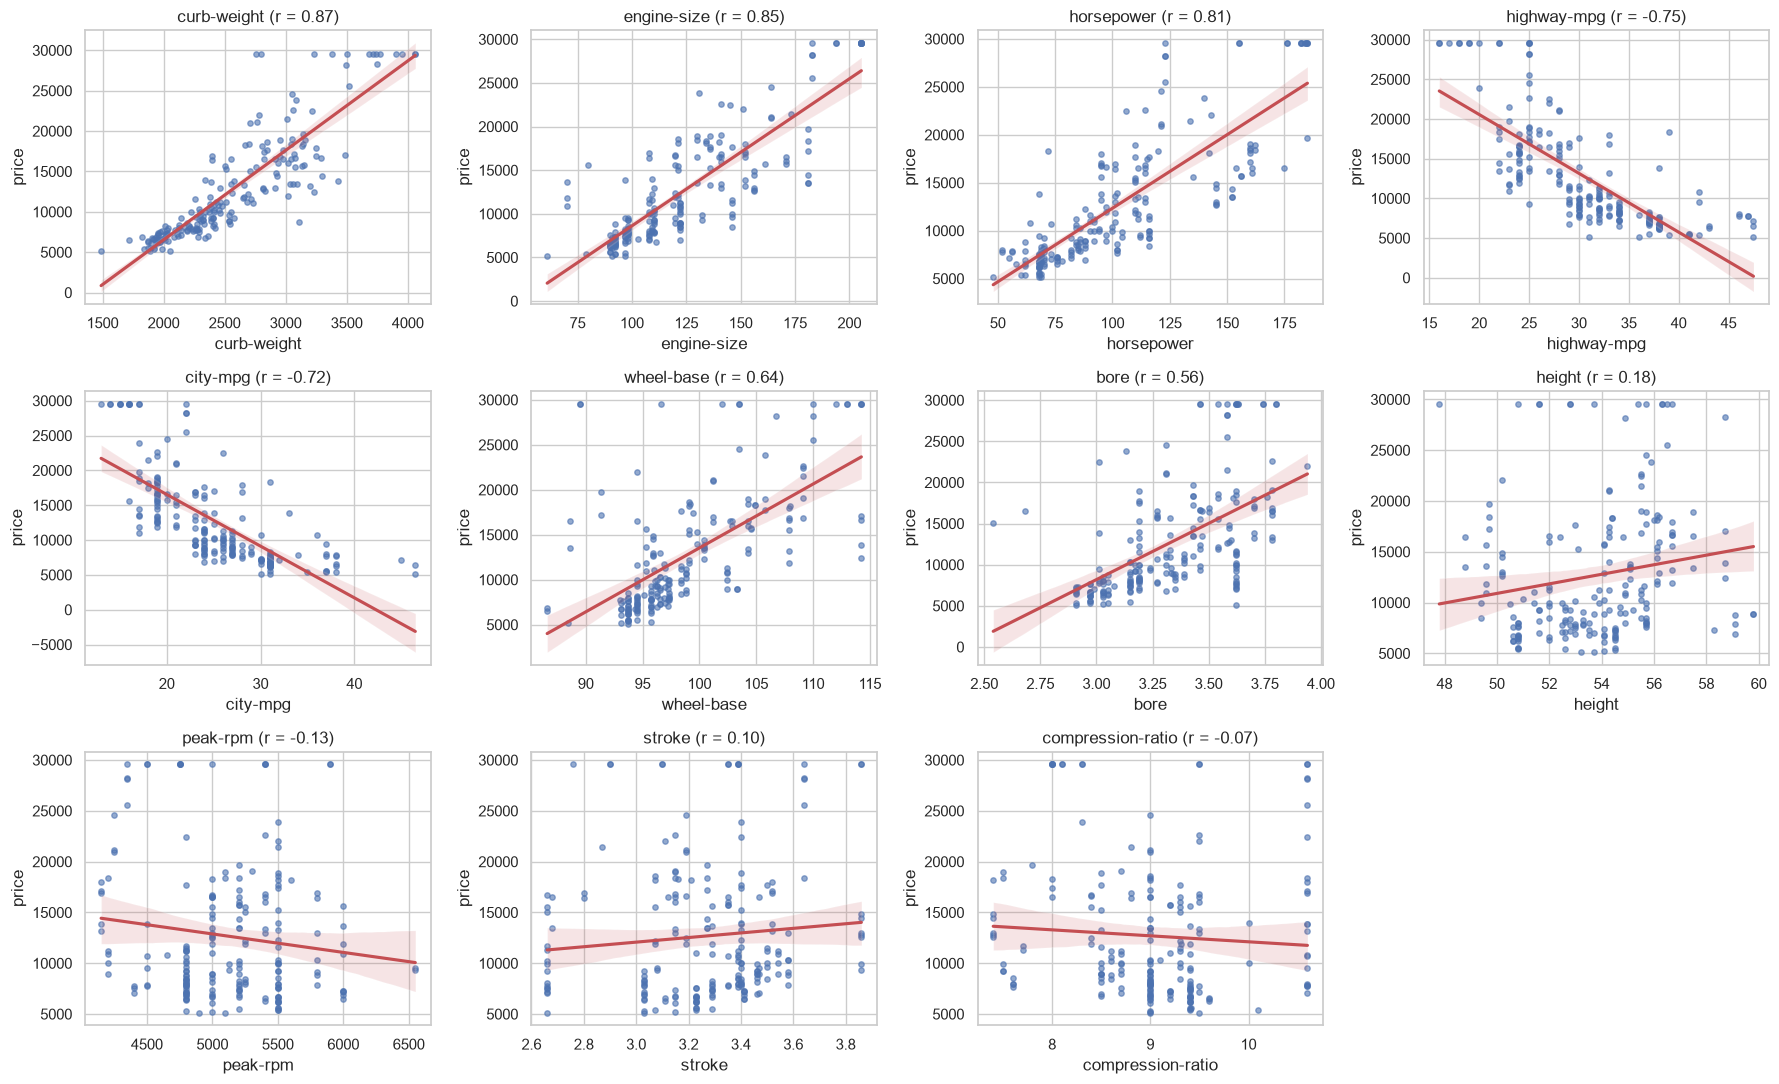

In [21]:
# Visualizing the correlation coefficients for the continuous predictors and the target variable.

fig, axes = plt.subplots(3, 4, figsize=(18, 11))
for ax, c in zip(axes.ravel(), corr.index):
    sns.regplot(data=df, x=c, y=TARGET, ax=ax, scatter_kws={"s": 15, "alpha": .6}, line_kws={"color": "C3"})
    ax.set_title(f"{c} (r = {corr.loc[c, 'pearson r']:.2f})")
axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.show()

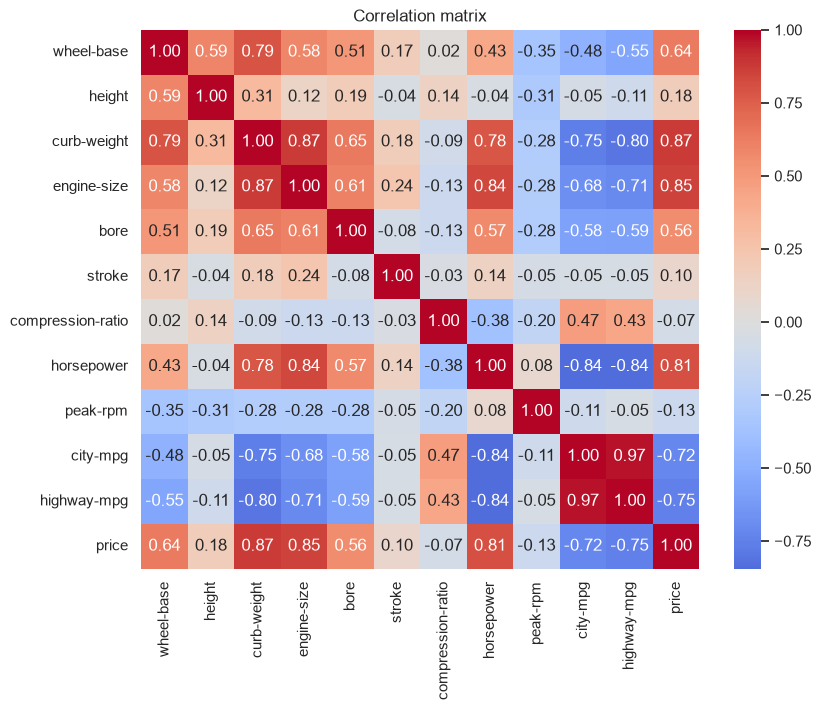

In [22]:
# Visualizing the correlation matrix for the continuous predictors and the target variable.

plt.figure(figsize=(9, 7))
sns.heatmap(df[CONT + [TARGET]].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix")
plt.show()

Curb weight has the highest positive correlation with price, with Pearson r = 0.8741 and Spearman rho = 0.9157 (both p < 0.0001). Engine size ranks second with Pearson r = 0.8522, and horsepower ranks third with r = 0.8094. Highway mpg and city mpg show strong negative correlations with price at r = -0.7455 and r = -0.7180. Peak rpm (r = -0.1313, p = 0.0638), stroke (r = 0.0959, p = 0.1769), and compression ratio (r = -0.0706, p = 0.3203) do not have statistically significant linear relationships with price at the 5% level. The correlation matrix shows high correlation among the top continuous predictors, such as curb weight with engine size at 0.87 and horsepower with curb weight at 0.78.

### Categorical variables vs price
One-way ANOVA tests whether mean price differs between categories. Eta squared (η²) is the share of price variance explained by the category. Kruskal-Wallis is added as a check that does not assume normality.

In [23]:
# Calculating the ANOVA and Kruskal-Wallis test statistics for the categorical predictors and the target variable.

rows = []
for c in CAT:
    groups = [g[TARGET].values for _, g in df.groupby(c) if len(g) > 1]
    F, p = stats.f_oneway(*groups)
    H, pk = stats.kruskal(*groups)
    ss_between = sum(len(g)*(g.mean()-df[TARGET].mean())**2 for g in groups)
    eta2 = ss_between / ((df[TARGET]-df[TARGET].mean())**2).sum()
    rows.append([c, df[c].nunique(), F, p, pk, eta2])
anova = pd.DataFrame(rows, columns=["variable","levels","F","p (ANOVA)","p (Kruskal)","eta2"]).set_index("variable")
anova = anova.sort_values("eta2", ascending=False)
anova.round(4)

,levels,F,p (ANOVA),p (Kruskal),eta2
variable,,,,,
make,22,33.7487,0.0000,0.0000,0.7900
num-of-cylinders,7,62.7215,0.0000,0.0000,0.5427
drive-wheels,3,81.0553,0.0000,0.0000,0.4514
fuel-system,8,27.7615,0.0000,0.0000,0.4195
engine-type,6,9.0931,0.0000,0.0000,0.1899
symboling,6,8.7546,0.0000,0.0000,0.1841
body-style,5,7.3896,0.0000,0.0001,0.1316
engine-location,2,14.2787,0.0002,0.0217,0.0673
aspiration,2,13.3932,0.0003,0.0000,0.0634


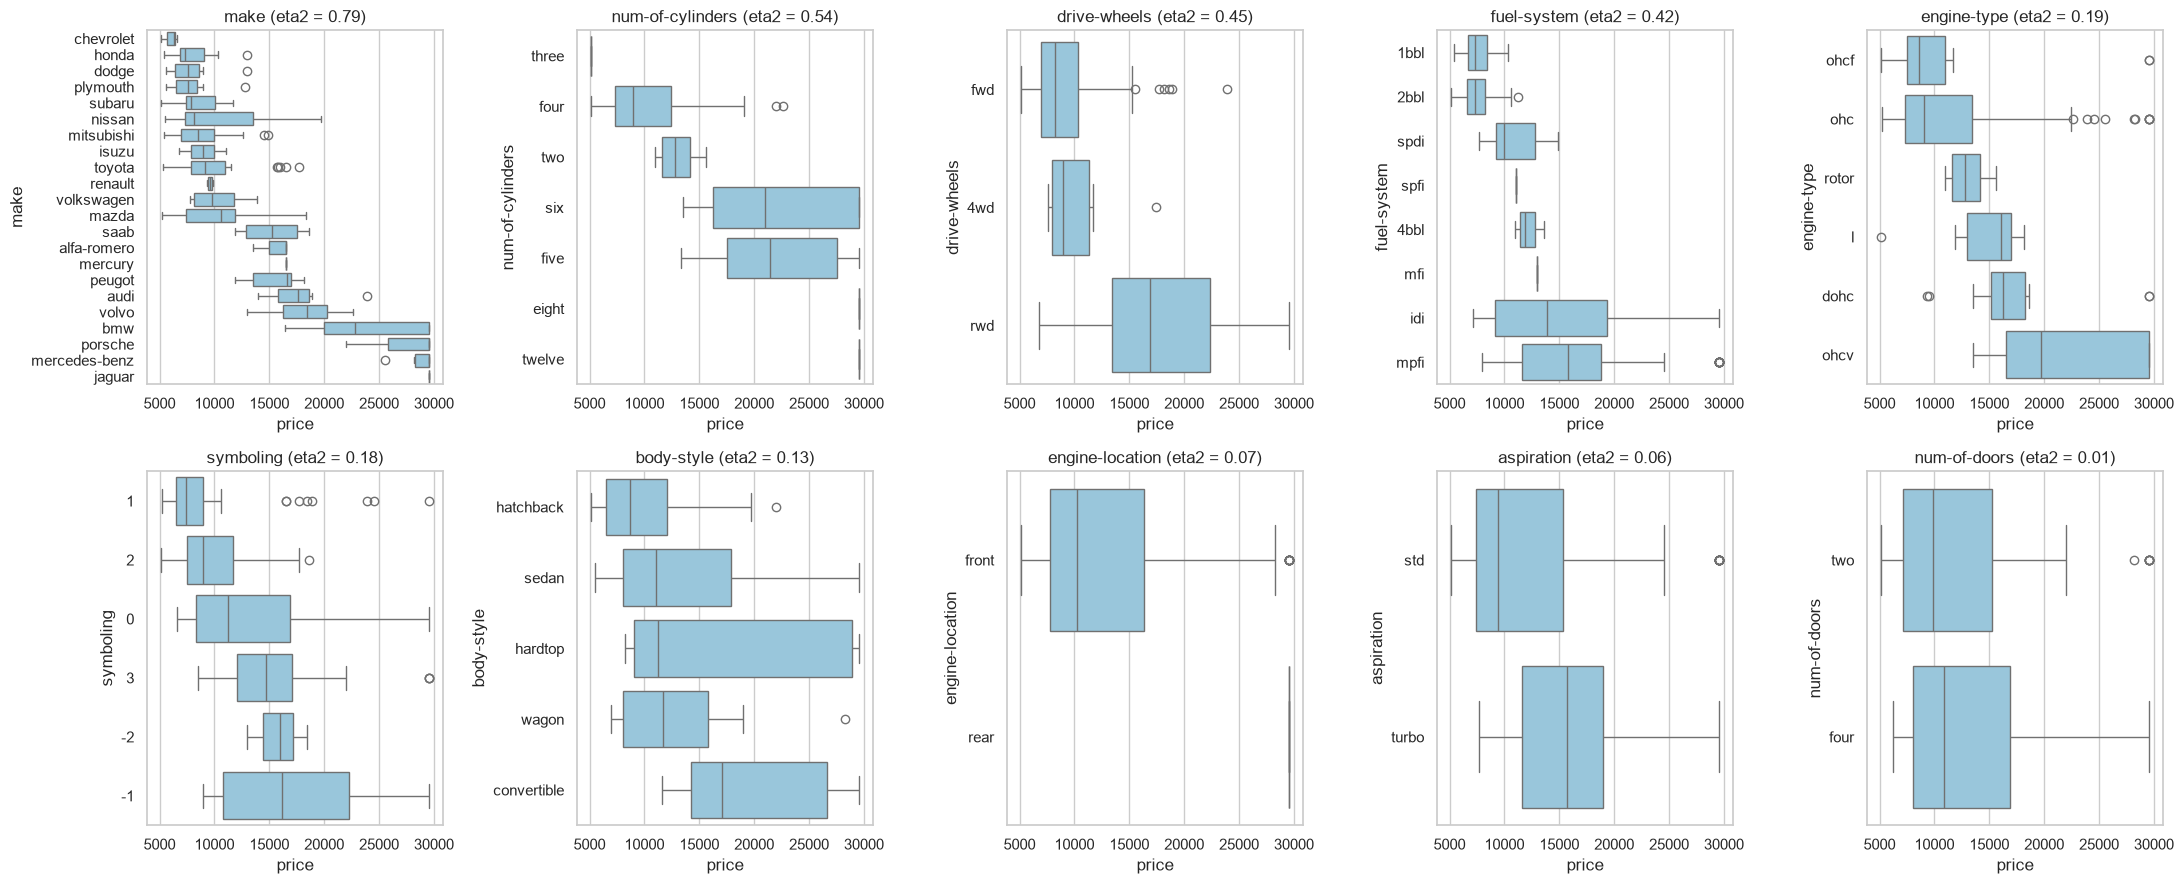

In [24]:
# Visualizing the ANOVA and Kruskal-Wallis test statistics for the categorical predictors and the target variable.

fig, axes = plt.subplots(2, 5, figsize=(22, 9))
for ax, c in zip(axes.ravel(), anova.index):
    order = df.groupby(c)[TARGET].median().sort_values().index
    sns.boxplot(data=df, y=c, x=TARGET, order=order, ax=ax, color="#8ecae6")
    ax.set_title(f"{c} (eta2 = {anova.loc[c, 'eta2']:.2f})")
plt.tight_layout()
plt.show()

Make explains the largest share of price variance among categoricals, with eta squared = 0.7900 and ANOVA F = 33.75 (p < 0.0001). Cylinder count is second with eta squared = 0.5427 (F = 62.72), and drive wheels is third with eta squared = 0.4514 (F = 81.06). Fuel system also has a strong effect with eta squared = 0.4195. The Kruskal-Wallis test confirms significant differences across groups for all four variables (p < 0.0001). Number of doors shows no statistically significant association with price (F = 1.66, p = 0.1984), explaining less than 1% of price variance.

### Two categorical variables
Chi-square tests of independence with Cramér's V as the effect size, followed by the joint effect on price.

In [25]:
# Calculating Cramer's V for pairs of categorical predictors.

def cramers_v(a, b):
    ct = pd.crosstab(df[a], df[b])
    chi2, p, dof, _ = stats.chi2_contingency(ct)
    n = ct.values.sum()
    k = min(ct.shape) - 1
    return chi2, p, np.sqrt(chi2 / (n * k))

pairs = [("drive-wheels","body-style"), ("body-style","num-of-doors"), ("aspiration","num-of-cylinders"),
         ("drive-wheels","num-of-cylinders"), ("make","body-style")]
res = pd.DataFrame([(a, b, *cramers_v(a, b)) for a, b in pairs], columns=["var 1","var 2","chi2","p","Cramer's V"])
res.round(4)

,var 1,var 2,chi2,p,Cramer's V
0,drive-wheels,body-style,27.4959,0.0006,0.2622
1,body-style,num-of-doors,116.3404,0.0000,0.7627
2,aspiration,num-of-cylinders,10.5054,0.1049,0.2292
3,drive-wheels,num-of-cylinders,49.7510,0.0000,0.3527
4,make,body-style,160.3528,0.0000,0.4477


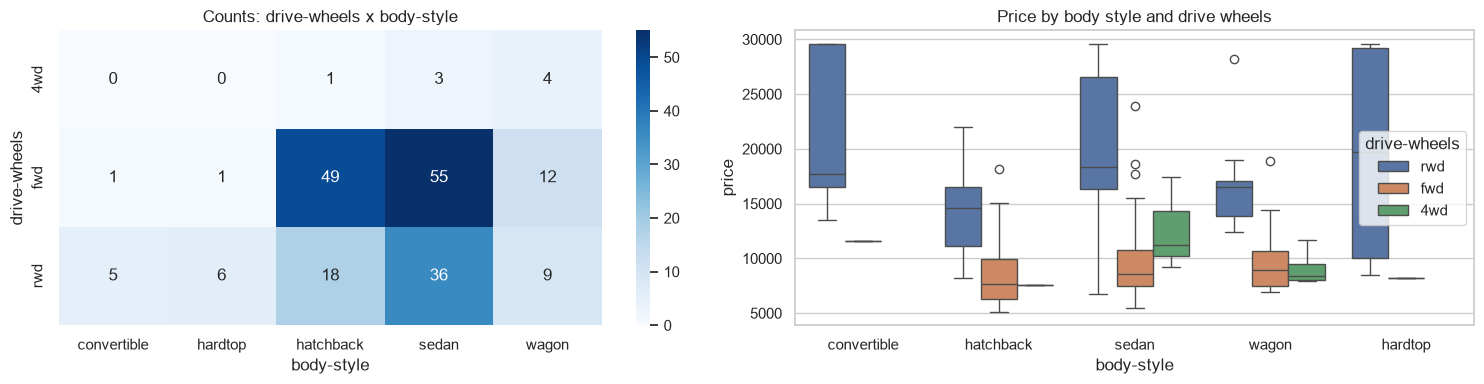

C:\Users\MARKO\AppData\Local\Temp\ipykernel_2956\1810769493.py:13: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  m = ols('price ~ C(Q("drive-wheels")) * C(Q("body-style"))', data=df).fit()
d:\Anaconda3\envs\oop2\Lib\site-packages\statsmodels\base\model.py:1988: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 4, but rank is 3
  res = self.wald_test(


,sum_sq,df,F,PR(>F)
"C(Q(""drive-wheels""))",4.232269e+09,2.0,95.8521,0.0000
"C(Q(""body-style""))",4.406710e+08,4.0,4.9901,0.0024
"C(Q(""drive-wheels"")):C(Q(""body-style""))",2.598721e+08,8.0,1.4714,0.1701
Residual,4.128413e+09,187.0,NaN,NaN


In [26]:
# Visualizing the counts and price by drive-wheels and body-style.

ct = pd.crosstab(df["drive-wheels"], df["body-style"])
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
sns.heatmap(ct, annot=True, fmt="d", cmap="Blues", ax=ax[0])
ax[0].set_title("Counts: drive-wheels x body-style")
sns.boxplot(data=df, x="body-style", y=TARGET, hue="drive-wheels", ax=ax[1])
ax[1].set_title("Price by body style and drive wheels")
plt.tight_layout()
plt.show()

# Two-way ANOVA on price (type II) for the main effects and their interaction
m = ols('price ~ C(Q("drive-wheels")) * C(Q("body-style"))', data=df).fit()
sm.stats.anova_lm(m, typ=2).round(4)

The chi-square tests indicate strong relationships between body style and number of doors with Cramér's V = 0.7627 (p < 0.0001), and between make and body style with Cramér's V = 0.4477 (p < 0.0001). Drive wheels and body style show a moderate association with Cramér's V = 0.2622 (p = 0.0006). In the two-way ANOVA on price, drive wheels has a large main effect with F = 95.85 (p < 0.0001), while body style has an F of 4.99 (p = 0.0024). The interaction between drive wheels and body style is not statistically significant (F = 1.47, p = 0.1701). This indicates that the price premium for rear wheel drive remains consistent across body styles.

## Q5. Main price drivers and feature selection
Continuous predictors are ranked by absolute Pearson correlation and the F-statistic of a simple regression on price. Categorical predictors are ranked by ANOVA F and η². Both sets are put on the same scale as "share of price variance explained" (r² and η²).

In [27]:
# Ranking the predictors by variance explained (R-squared) for continuous and categorical predictors.

Xc = df[CONT]
F, p = f_regression(Xc, df[TARGET])
cont_rank = pd.DataFrame({"type": "continuous", "F": F, "p": p, "variance explained": corr.loc[CONT, "pearson r"]**2}, index=CONT)
cat_rank = pd.DataFrame({"type": "categorical", "F": anova["F"], "p": anova["p (ANOVA)"], "variance explained": anova["eta2"]})
rank = pd.concat([cont_rank, cat_rank]).sort_values("variance explained", ascending=False)
rank["rank"] = range(1, len(rank)+1)
rank.round(4)

,type,F,p,variance explained,rank
make,categorical,33.7487,0.0000,0.7900,1
curb-weight,continuous,641.1092,0.0000,0.7640,2
engine-size,continuous,525.3237,0.0000,0.7263,3
horsepower,continuous,376.2339,0.0000,0.6552,4
highway-mpg,continuous,247.7699,0.0000,0.5558,5
num-of-cylinders,categorical,62.7215,0.0000,0.5427,6
city-mpg,continuous,210.6446,0.0000,0.5155,7
drive-wheels,categorical,81.0553,0.0000,0.4514,8
fuel-system,categorical,27.7615,0.0000,0.4195,9
wheel-base,continuous,136.4198,0.0000,0.4079,10


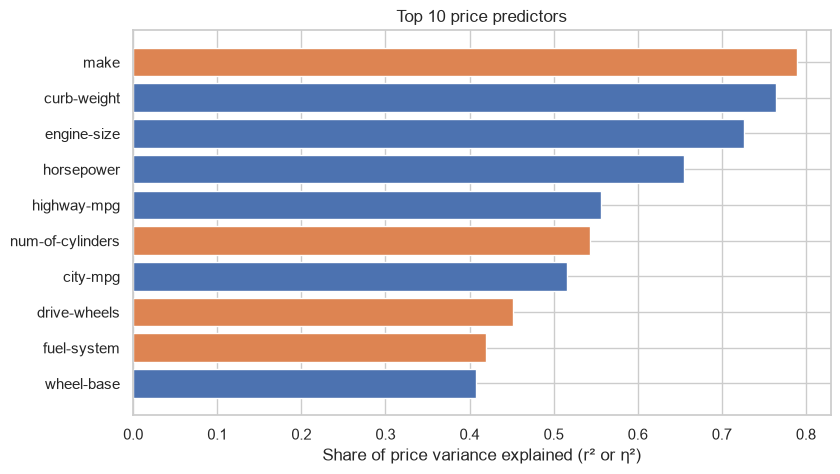

In [28]:
# Visualizing the top 10 predictors by variance explained.

top = rank.head(10).iloc[::-1]
plt.figure(figsize=(9, 5))
plt.barh(top.index, top["variance explained"], color=top["type"].map({"continuous": "C0", "categorical": "C1"}))
plt.xlabel("Share of price variance explained (r² or η²)")
plt.title("Top 10 price predictors")
plt.show()

### Multicollinearity among the strongest continuous predictors

In [29]:
strong = rank[(rank.type == "continuous") & (rank["p"] < .05)].index[:6]
print("Correlation among top continuous predictors:")
print(df[strong].corr().round(2))

Correlation among top continuous predictors:
             curb-weight  engine-size  horsepower  highway-mpg  city-mpg  wheel-base
curb-weight         1.00         0.87        0.78        -0.80     -0.75        0.79
engine-size         0.87         1.00        0.84        -0.71     -0.68        0.58
horsepower          0.78         0.84        1.00        -0.84     -0.84        0.43
highway-mpg        -0.80        -0.71       -0.84         1.00      0.97       -0.55
city-mpg           -0.75        -0.68       -0.84         0.97      1.00       -0.48
wheel-base          0.79         0.58        0.43        -0.55     -0.48        1.00


On the unified scale of variance explained, make ranks first at 0.7900, followed by curb weight at 0.7640, engine size at 0.7263, horsepower at 0.6552, highway mpg at 0.5558, and cylinder count at 0.5427. The correlation matrix confirms severe multicollinearity among the continuous variables. Curb weight correlates with engine size at 0.87, with horsepower at 0.78, and with highway mpg at -0.80. City mpg and highway mpg correlate with each other at 0.97. Retaining all these measures would create redundancy in a predictive model. A parsimonious selection needs one vehicle mass metric, one power metric, and the top categorical factors. My recommended non-redundant set is curb weight, horsepower, make, and drive wheels.

### Recommendations

I recommend pricing inventory using four primary factors: make, curb weight, horsepower, and drive wheels. Heavier cars and cars with higher horsepower command higher prices, while rear wheel drive adds a substantial premium over front wheel drive. Brand badge also shifts baseline price upward, with luxury names like Jaguar and Mercedes-Benz selling well above mass-market brands like Toyota and Chevrolet. Correlation is not causation, so adding dead weight to a chassis does not create market value on its own. As a practical pricing rule, I suggest establishing a baseline price by make and drivetrain, adding price increments for curb weight and horsepower, and then adjusting for vehicle condition.